In [1]:
%pip install pandas numpy matplotlib seaborn openpyxl scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import pandas as pd

# Works when Jupyter starts in RetailPulse or RetailPulse/notebooks.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FILE = ROOT / "data" / "online_retail_II.xlsx"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Place the extracted Excel file here: {DATA_FILE}")

excel = pd.ExcelFile(DATA_FILE)
print("Worksheets:", excel.sheet_names)

Worksheets: ['Year 2009-2010', 'Year 2010-2011']


In [3]:
sheets = {
    name: pd.read_excel(
        excel,
        sheet_name=name,
        dtype={
            "Invoice": "string",
            "StockCode": "string",
            "Customer ID": "string",
        },
    )
    for name in excel.sheet_names
}

for name, df in sheets.items():
    print(f"\n{name}: {len(df):,} rows")
    display(df.head())


Year 2009-2010: 525,461 rows


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom



Year 2010-2011: 541,910 rows


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [4]:
summary = []

for name, df in sheets.items():
    dates = pd.to_datetime(df["InvoiceDate"], errors="coerce")

    summary.append({
        "Sheet": name,
        "Rows": len(df),
        "Start": dates.min(),
        "End": dates.max(),
        "Missing customer IDs": df["Customer ID"].isna().sum(),
        "Negative quantities": df["Quantity"].lt(0).sum(),
        "Zero or negative prices": df["Price"].le(0).sum(),
        "Potential duplicate rows": df.duplicated().sum(),
    })

display(pd.DataFrame(summary))

,Sheet,Rows,Start,End,Missing customer IDs,Negative quantities,Zero or negative prices,Potential duplicate rows
0,Year 2009-2010,525461,2009-12-01 07:45:00,2010-12-09 20:01:00,107927,12326,3690,6865
1,Year 2010-2011,541910,2010-12-01 08:26:00,2011-12-09 12:50:00,135080,10624,2517,5268


In [5]:
# Compare complete transaction rows across the worksheets.
first = sheets["Year 2009-2010"]
second = sheets["Year 2010-2011"]

columns = first.columns.tolist()

# Unique rows avoid multiplying matches during the comparison.
overlap = first.drop_duplicates().merge(
    second.drop_duplicates(),
    on=columns,
    how="inner",
)

print(f"Identical transaction rows shared across sheets: {len(overlap):,}")

if not overlap.empty:
    print("First shared date:", overlap["InvoiceDate"].min())
    print("Last shared date:", overlap["InvoiceDate"].max())
    display(overlap.head())

# Combine with a source label so each row remains traceable.
raw = pd.concat(
    [
        first.assign(SourceSheet="Year 2009-2010"),
        second.assign(SourceSheet="Year 2010-2011"),
    ],
    ignore_index=True,
)

print(f"\nCombined raw rows: {len(raw):,}")

Identical transaction rows shared across sheets: 22,202
First shared date: 2010-12-01 08:26:00
Last shared date: 2010-12-09 20:01:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom



Combined raw rows: 1,067,371


In [6]:
transaction_columns = first.columns.tolist()

working = raw.copy()

# Number identical occurrences separately within each source sheet.
working["_Occurrence"] = working.groupby(
    ["SourceSheet"] + transaction_columns,
    dropna=False,
    sort=False,
).cumcount()

# Match on all original fields plus occurrence number.
cross_sheet_duplicate = working.duplicated(
    subset=transaction_columns + ["_Occurrence"],
    keep="first",
)

transactions = working.loc[~cross_sheet_duplicate].drop(
    columns="_Occurrence"
).copy()

print(f"Original rows: {len(raw):,}")
print(f"Repeated copies removed: {cross_sheet_duplicate.sum():,}")
print(f"Remaining rows: {len(transactions):,}")

Original rows: 1,067,371
Repeated copies removed: 22,523
Remaining rows: 1,044,848


In [7]:
transactions["InvoiceDate"] = pd.to_datetime(
    transactions["InvoiceDate"], errors="coerce"
)

for column in ["Quantity", "Price"]:
    transactions[column] = pd.to_numeric(
        transactions[column], errors="coerce"
    )

for column in ["Invoice", "StockCode", "Customer ID"]:
    transactions[column] = (
        transactions[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# Identify cancellations and negative-quantity records.
is_return = (
    transactions["Invoice"].str.upper().str.startswith("C", na=False)
    | transactions["Quantity"].lt(0)
)

returns = transactions.loc[is_return].copy()

# Require usable fields for purchase analysis.
valid_purchase = (
    ~is_return
    & transactions["InvoiceDate"].notna()
    & transactions["Invoice"].notna()
    & transactions["StockCode"].notna()
    & transactions["Quantity"].gt(0)
    & transactions["Price"].gt(0)
)

purchases = transactions.loc[valid_purchase].copy()
purchases["SalesValue"] = purchases["Quantity"] * purchases["Price"]

# Customer analysis needs an identified customer.
customer_purchases = purchases.loc[
    purchases["Customer ID"].notna()
].copy()

# Preserve other records for investigation.
review_rows = transactions.loc[
    ~is_return & ~valid_purchase
].copy()

assert len(transactions) == len(purchases) + len(returns) + len(review_rows)

print(f"Purchase rows: {len(purchases):,}")
print(f"Return/cancellation rows: {len(returns):,}")
print(f"Other rows requiring review: {len(review_rows):,}")
print(f"Purchase rows with customer IDs: {len(customer_purchases):,}")
print(f"Identified purchasing customers: {customer_purchases['Customer ID'].nunique():,}")
print(f"Gross purchase value: £{purchases['SalesValue'].sum():,.2f}")

Purchase rows: 1,019,654
Return/cancellation rows: 22,558
Other rows requiring review: 2,636
Purchase rows with customer IDs: 791,045
Identified purchasing customers: 5,878
Gross purchase value: £20,533,741.92


In [8]:
# Common product codes follow five digits, sometimes with letter suffixes.
# Different formats are review candidates, not automatically invalid.
standard_code = purchases["StockCode"].str.fullmatch(
    r"\d{5}[A-Za-z]*", na=False
)

description_flag = (
    purchases["Description"]
    .astype("string")
    .str.contains(
        r"\b(postage|carriage|manual|discount|commission|"
        r"bank charges|amazon fee|adjustment|gift voucher)\b",
        case=False,
        na=False,
    )
)

review_mask = ~standard_code | description_flag

code_review = (
    purchases.loc[review_mask]
    .groupby("StockCode", dropna=False)
    .agg(
        ExampleDescription=("Description", "first"),
        Rows=("StockCode", "size"),
        Units=("Quantity", "sum"),
        GrossValue=("SalesValue", "sum"),
    )
    .sort_values("GrossValue", ascending=False)
    .reset_index()
)

print(f"Product codes to review: {len(code_review):,}")

with pd.option_context(
    "display.max_rows", 100,
    "display.max_colwidth", 60,
):
    display(code_review.head(100).round(2))

C:\Users\crawlo\AppData\Local\Temp\ipykernel_49476\3231081533.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(


Product codes to review: 45


,StockCode,ExampleDescription,Rows,Units,GrossValue
0,M,Manual,856,9931,339614.89
1,DOT,DOTCOM POSTAGE,1415,1415,309854.11
2,POST,POSTAGE,1851,5363,125682.42
3,AMAZONFEE,AMAZON FEE,3,3,20467.80
4,C2,CARRIAGE,267,268,13426.00
5,B,Adjust bad debt,1,1,11062.06
6,ADJUST,Adjustment by john on 26/01/2010 16,36,36,8897.93
7,23444,Next Day Carriage,79,79,1200.00
8,23099,FRENCH CARRIAGE LANTERN,59,137,925.35
9,ADJUST2,Adjustment by Peter on Jun 25 2010,3,3,731.05


In [9]:
# Exclude SourceSheet and calculated fields when comparing transactions.
duplicate_candidates = purchases.duplicated(
    subset=transaction_columns,
    keep="first",
)

missing_description = (
    purchases["Description"].isna()
    | purchases["Description"].astype("string").str.strip().eq("").fillna(False)
)

print(
    "Potential duplicate purchase rows retained:",
    f"{duplicate_candidates.sum():,}",
)

print(
    "Gross value associated with those duplicate candidates:",
    f"£{purchases.loc[duplicate_candidates, 'SalesValue'].sum():,.2f}",
)

print(
    "Purchase rows missing descriptions:",
    f"{missing_description.sum():,}",
)

Potential duplicate purchase rows retained: 11,741
Gross value associated with those duplicate candidates: £57,481.47
Purchase rows missing descriptions: 0


In [10]:
print(code_review.to_string(index=False))

   StockCode                  ExampleDescription  Rows  Units  GrossValue
           M                              Manual   856   9931  339614.890
         DOT                      DOTCOM POSTAGE  1415   1415  309854.110
        POST                             POSTAGE  1851   5363  125682.420
   AMAZONFEE                          AMAZON FEE     3      3   20467.800
          C2                            CARRIAGE   267    268   13426.000
           B                     Adjust bad debt     1      1   11062.060
      ADJUST Adjustment by john on 26/01/2010 16    36     36    8897.930
       23444                   Next Day Carriage    79     79    1200.000
       23099             FRENCH CARRIAGE LANTERN    59    137     925.350
     ADJUST2 Adjustment by Peter on Jun 25 2010      3      3     731.050
      85168B        BLACK BAROQUE CARRIAGE CLOCK    53     73     662.120
gift_0001_30  Dotcomgiftshop Gift Voucher £30.00    24     24     610.090
BANK CHARGES                        Ba

In [11]:
# Use uppercase only for classification; preserve original stock codes.
codes = purchases["StockCode"].str.upper()

exclusion_reasons = {
    "M": "Manual entry: product unknown",
    "DOT": "Postage",
    "POST": "Postage",
    "C2": "Carriage charge",
    "23444": "Next-day carriage charge",
    "AMAZONFEE": "Marketplace fee",
    "BANK CHARGES": "Bank charge",
    "B": "Bad-debt adjustment",
    "ADJUST": "Adjustment",
    "ADJUST2": "Adjustment",
    "D": "Discount entry",
    "TEST001": "Test product",
    "TEST002": "Test product",
    "S": "Samples: excluded from normal merchandise demand",
    "22016": "Gift voucher",
}

reason = codes.map(exclusion_reasons)
reason = reason.mask(
    codes.str.startswith("GIFT_", na=False),
    "Gift voucher",
)

excluded_purchases = purchases.loc[reason.notna()].copy()
excluded_purchases["ExclusionReason"] = reason.loc[reason.notna()]

merchandise = purchases.loc[reason.isna()].copy()

customer_merchandise = merchandise.loc[
    merchandise["Customer ID"].notna()
].copy()

assert len(purchases) == len(merchandise) + len(excluded_purchases)

print(f"Merchandise purchase rows: {len(merchandise):,}")
print(f"Excluded rows: {len(excluded_purchases):,}")
print(f"Excluded gross value: £{excluded_purchases['SalesValue'].sum():,.2f}")
print(f"Gross merchandise purchase value: £{merchandise['SalesValue'].sum():,.2f}")
print(f"Identified merchandise customers: {customer_merchandise['Customer ID'].nunique():,}")

display(
    excluded_purchases.groupby("ExclusionReason")
    .agg(
        Rows=("StockCode", "size"),
        GrossValue=("SalesValue", "sum"),
    )
    .sort_values("GrossValue", ascending=False)
    .round(2)
)

Merchandise purchase rows: 1,015,008
Excluded rows: 4,646
Excluded gross value: £834,070.79
Gross merchandise purchase value: £19,699,671.13
Identified merchandise customers: 5,852


,Rows,GrossValue
ExclusionReason,,
Postage,3266,435536.53
Manual entry: product unknown,861,339629.94
Marketplace fee,3,20467.80
Carriage charge,267,13426.00
Bad-debt adjustment,1,11062.06
Adjustment,39,9628.98
Gift voucher,78,1839.50
Next-day carriage charge,79,1200.00
Bank charge,34,519.24


In [12]:
# Historical reference date, not today's date.
snapshot_date = (
    merchandise["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)
window_start = snapshot_date - pd.Timedelta(days=365)

rfm_source = customer_merchandise.loc[
    customer_merchandise["InvoiceDate"].ge(window_start)
    & customer_merchandise["InvoiceDate"].lt(snapshot_date)
].copy()

rfm = (
    rfm_source.groupby("Customer ID")
    .agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("SalesValue", "sum"),
    )
)

rfm["Recency"] = (
    snapshot_date - rfm["LastPurchase"].dt.normalize()
).dt.days

rfm = rfm[["Recency", "Frequency", "Monetary"]]

print("Window starts:", window_start.date())
print("Reference date:", snapshot_date.date())
print(f"Customers purchasing within this window: {len(rfm):,}")

display(rfm.head().round(2))
display(rfm.describe().round(2))

Window starts: 2010-12-10
Reference date: 2011-12-10
Customers purchasing within this window: 4,261


,Recency,Frequency,Monetary
Customer ID,,,
12346,326,1,77183.60
12347,3,6,3598.21
12348,76,4,1437.24
12349,19,1,1457.55
12350,311,1,294.40


,Recency,Frequency,Monetary
count,4261.00,4261.00,4261.00
mean,88.47,4.14,1983.18
std,94.16,7.33,8701.52
min,1.00,1.00,3.75
25%,18.00,1.00,302.20
50%,51.00,2.00,659.46
75%,134.00,4.00,1612.69
max,365.00,190.00,279138.02


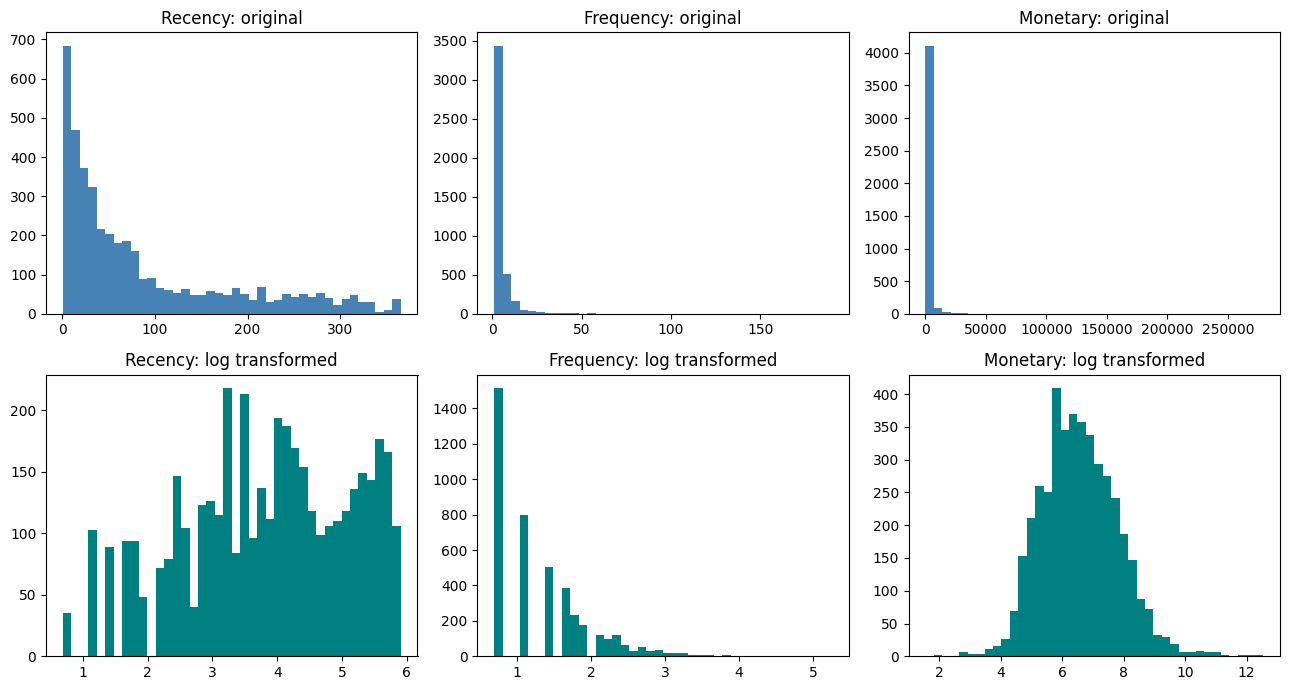

Prepared 4,261 customers for clustering.


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

features = ["Recency", "Frequency", "Monetary"]
X = rfm[features].astype(float).copy()

assert len(X) >= 10, "Too few customers for this clustering comparison."
assert np.isfinite(X.to_numpy()).all(), "RFM contains missing or infinite values."
assert X.gt(0).all().all(), "Expected positive RFM values."

X_log = np.log1p(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for i, feature in enumerate(features):
    axes[0, i].hist(X[feature], bins=40, color="steelblue")
    axes[0, i].set_title(f"{feature}: original")

    axes[1, i].hist(X_log[feature], bins=40, color="teal")
    axes[1, i].set_title(f"{feature}: log transformed")

plt.tight_layout()
plt.show()

print(f"Prepared {len(X):,} customers for clustering.")

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_models = {}
results = []

for k in range(2, 9):
    print(f"Evaluating {k} clusters...", flush=True)

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
    )
    labels = model.fit_predict(X_scaled)

    # Fixed sample keeps comparisons reproducible and limits computation.
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=42,
    )

    sizes = pd.Series(labels).value_counts()

    cluster_models[k] = model
    results.append({
        "Clusters": k,
        "Silhouette": score,
        "SmallestGroup": sizes.min(),
        "LargestGroup": sizes.max(),
        "Inertia": model.inertia_,
    })

cluster_results = pd.DataFrame(results)
display(cluster_results.round(4))

Evaluating 2 clusters...
Evaluating 3 clusters...
Evaluating 4 clusters...
Evaluating 5 clusters...
Evaluating 6 clusters...
Evaluating 7 clusters...
Evaluating 8 clusters...


,Clusters,Silhouette,SmallestGroup,LargestGroup,Inertia
0,2,0.4333,1654,2607,6378.3105
1,3,0.3481,690,1923,4804.8398
2,4,0.3445,695,1554,3872.7506
3,5,0.3223,306,1167,3235.1331
4,6,0.3179,320,955,2806.2869
5,7,0.3059,173,846,2503.7830
6,8,0.3075,216,829,2295.4014


In [15]:
best_k = int(
    cluster_results.loc[
        cluster_results["Silhouette"].idxmax(), "Clusters"
    ]
)

rfm_clustered = rfm.copy()
rfm_clustered["Cluster"] = cluster_models[best_k].labels_

cluster_profile = (
    rfm_clustered.groupby("Cluster")
    .agg(
        Customers=("Recency", "size"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum"),
    )
)

cluster_profile["CustomerSharePct"] = (
    cluster_profile["Customers"] / len(rfm_clustered) * 100
)

print(f"Provisional number of clusters: {best_k}")
display(cluster_profile.round(2))

Provisional number of clusters: 2


,Customers,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary,CustomerSharePct
Cluster,,,,,,
0,1654,17.0,5.0,1975.62,7184673.89,38.82
1,2607,93.0,1.0,352.70,1265669.01,61.18


In [16]:
segment_names = {
    0: "Recent, higher-value customers",
    1: "Less-recent, lower-frequency customers",
}

# These names apply specifically to the two-cluster result you shared.
assert best_k == 2, "Review cluster profiles before assigning these names."

rfm_clustered["Segment"] = rfm_clustered["Cluster"].map(segment_names)

segment_summary = (
    rfm_clustered.groupby("Segment")
    .agg(
        Customers=("Recency", "size"),
        MedianRecencyDays=("Recency", "median"),
        MedianInvoices=("Frequency", "median"),
        MedianGrossSpend=("Monetary", "median"),
        TotalGrossSpend=("Monetary", "sum"),
    )
)

segment_summary["CustomerSharePct"] = (
    segment_summary["Customers"] / segment_summary["Customers"].sum() * 100
)

segment_summary["GrossSpendSharePct"] = (
    segment_summary["TotalGrossSpend"]
    / segment_summary["TotalGrossSpend"].sum()
    * 100
)

display(segment_summary.round(2))

,Customers,MedianRecencyDays,MedianInvoices,MedianGrossSpend,TotalGrossSpend,CustomerSharePct,GrossSpendSharePct
Segment,,,,,,,
"Less-recent, lower-frequency customers",2607,93.0,1.0,352.70,1265669.01,61.18,14.98
"Recent, higher-value customers",1654,17.0,5.0,1975.62,7184673.89,38.82,85.02


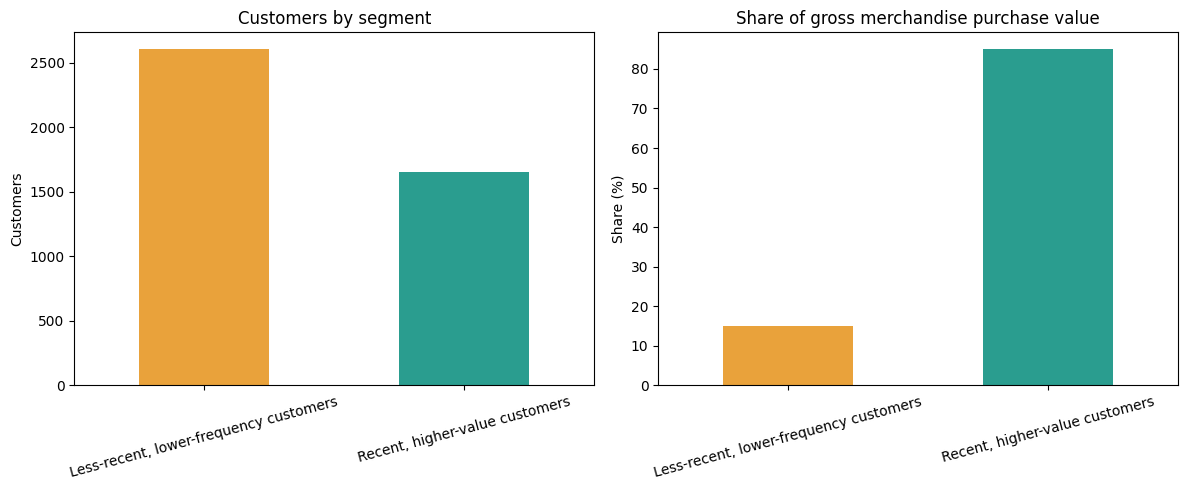

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

segment_summary["Customers"].plot.bar(
    ax=axes[0], color=["#E9A23B", "#2A9D8F"]
)
axes[0].set_title("Customers by segment")
axes[0].set_ylabel("Customers")

segment_summary["GrossSpendSharePct"].plot.bar(
    ax=axes[1], color=["#E9A23B", "#2A9D8F"]
)
axes[1].set_title("Share of gross merchandise purchase value")
axes[1].set_ylabel("Share (%)")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [18]:
display(cluster_results.round(4))

,Clusters,Silhouette,SmallestGroup,LargestGroup,Inertia
0,2,0.4333,1654,2607,6378.3105
1,3,0.3481,690,1923,4804.8398
2,4,0.3445,695,1554,3872.7506
3,5,0.3223,306,1167,3235.1331
4,6,0.3179,320,955,2806.2869
5,7,0.3059,173,846,2503.7830
6,8,0.3075,216,829,2295.4014


In [19]:
last_date = merchandise["InvoiceDate"].max().normalize()

forecast_source = merchandise.loc[
    merchandise["InvoiceDate"].lt(last_date)
].copy()

daily_sales = (
    forecast_source
    .set_index("InvoiceDate")
    .resample("D")
    .agg(
        Units=("Quantity", "sum"),
        GrossSales=("SalesValue", "sum"),
        Invoices=("Invoice", "nunique"),
    )
)

daily_sales.index.name = "Date"

print("Start:", daily_sales.index.min().date())
print("End:", daily_sales.index.max().date())
print("Excluded final date:", last_date.date())
print("Days with no purchase invoices:", daily_sales["Invoices"].eq(0).sum())

display(daily_sales.head())

Start: 2009-12-01
End: 2011-12-08
Excluded final date: 2011-12-09
Days with no purchase invoices: 135


,Units,GrossSales,Invoices
Date,,,
2009-12-01,26176,52600.88,117
2009-12-02,31891,62053.03,115
2009-12-03,49241,73125.24,124
2009-12-04,21307,39499.81,88
2009-12-05,5119,9803.05,30


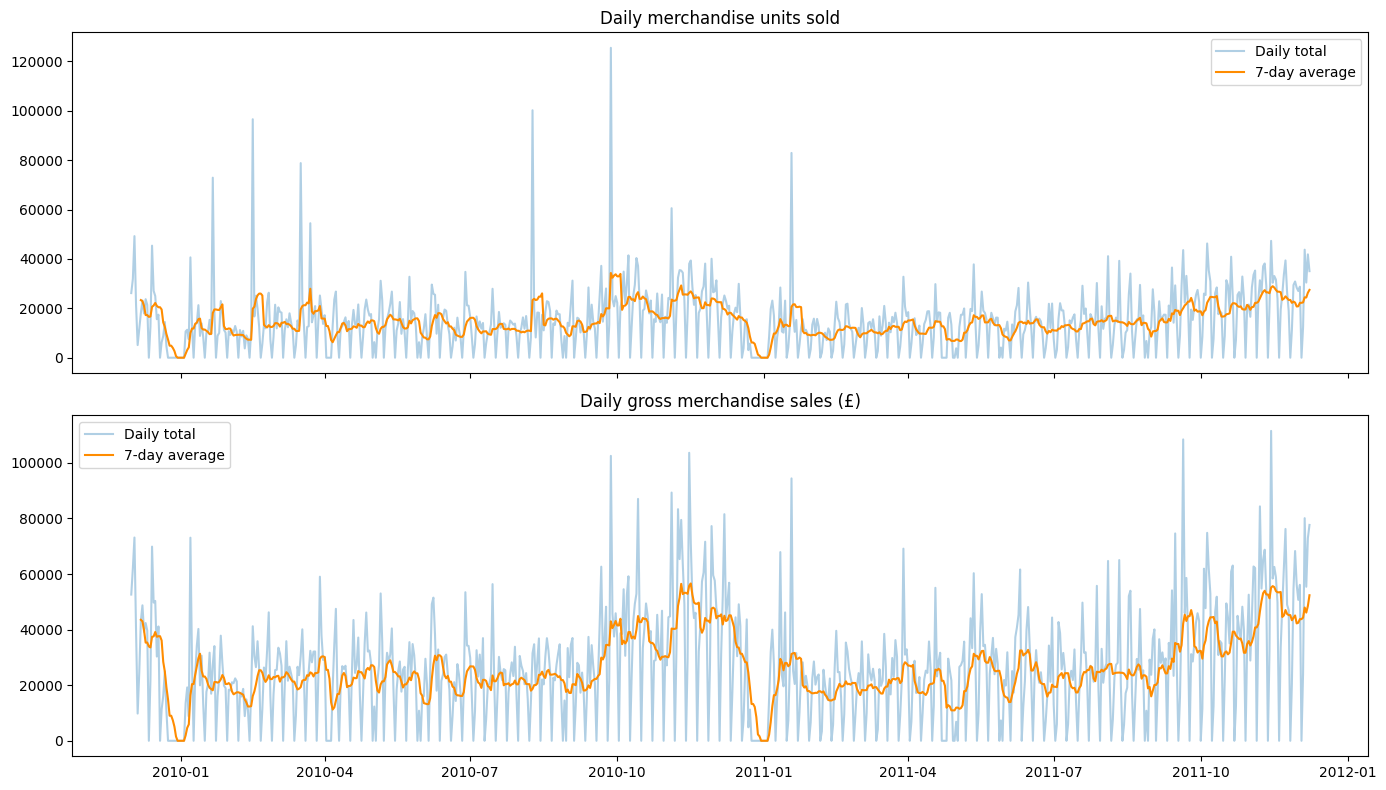

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

for ax, column, title in zip(
    axes,
    ["Units", "GrossSales"],
    ["Daily merchandise units sold", "Daily gross merchandise sales (£)"],
):
    ax.plot(
        daily_sales.index,
        daily_sales[column],
        alpha=0.35,
        label="Daily total",
    )
    ax.plot(
        daily_sales.index,
        daily_sales[column].rolling(7, min_periods=7).mean(),
        color="darkorange",
        label="7-day average",
    )
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

Training ends: 2011-11-08
Test period: 2011-11-09 to 2011-12-08
MAE: 6,150.53 units/day
RMSE: 7,790.05 units/day
WAPE: 23.83%


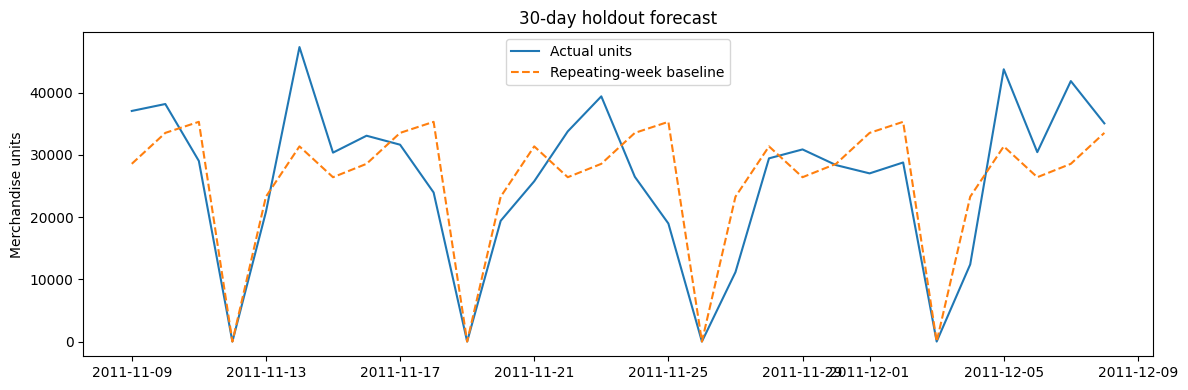

In [21]:
horizon = 30

train = daily_sales.iloc[:-horizon].copy()
test = daily_sales.iloc[-horizon:].copy()

assert len(train) >= 7, "At least one week of training data is required."

baseline = pd.Series(
    np.tile(train["Units"].iloc[-7:].to_numpy(), 5)[:horizon],
    index=test.index,
    name="ForecastUnits",
)

actual = test["Units"]
errors = actual - baseline

mae = errors.abs().mean()
rmse = np.sqrt((errors ** 2).mean())
wape = (
    errors.abs().sum() / actual.abs().sum() * 100
    if actual.abs().sum() > 0
    else np.nan
)

print(f"Training ends: {train.index.max().date()}")
print(f"Test period: {test.index.min().date()} to {test.index.max().date()}")
print(f"MAE: {mae:,.2f} units/day")
print(f"RMSE: {rmse:,.2f} units/day")
print(f"WAPE: {wape:.2f}%")

plt.figure(figsize=(12, 4))
plt.plot(test.index, actual, label="Actual units")
plt.plot(test.index, baseline, "--", label="Repeating-week baseline")
plt.title("30-day holdout forecast")
plt.ylabel("Merchandise units")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
zero_days = daily_sales.loc[daily_sales["Invoices"].eq(0)].copy()
zero_days["Weekday"] = zero_days.index.day_name()

print("Zero-sales days by weekday:")
print(zero_days["Weekday"].value_counts())

print("\nZero-sales dates in the test period:")
display(test.loc[test["Invoices"].eq(0)])

Zero-sales days by weekday:
Weekday
Saturday     104
Monday        11
Friday         7
Sunday         6
Thursday       3
Tuesday        2
Wednesday      2
Name: count, dtype: int64

Zero-sales dates in the test period:


,Units,GrossSales,Invoices
Date,,,
2011-11-12,0,0.0,0
2011-11-19,0,0.0,0
2011-11-26,0,0.0,0
2011-12-03,0,0.0,0


,MAE,RMSE,WAPE_pct
Repeating last week,6150.53,7790.05,23.83
Four-week weekday average,6328.71,8662.29,24.52


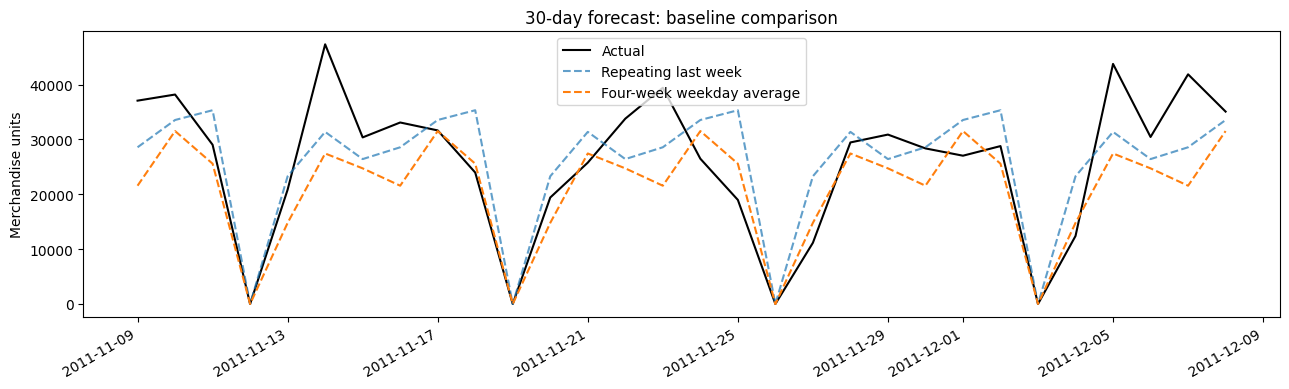

In [23]:
recent = train.tail(28).copy()

weekday_means = recent.groupby(
    recent.index.dayofweek
)["Units"].mean()

weekday_forecast = pd.Series(
    [weekday_means.loc[day] for day in test.index.dayofweek],
    index=test.index,
    name="FourWeekWeekdayAverage",
)

def forecast_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    errors = actual - predicted

    return {
        "MAE": np.abs(errors).mean(),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "WAPE_pct": (
            np.abs(errors).sum() / np.abs(actual).sum() * 100
            if np.abs(actual).sum() > 0 else np.nan
        ),
    }

comparison = pd.DataFrame({
    "Repeating last week": forecast_metrics(test["Units"], baseline),
    "Four-week weekday average": forecast_metrics(
        test["Units"], weekday_forecast
    ),
}).T

display(comparison.round(2))

fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(test.index, test["Units"], label="Actual", color="black")
ax.plot(test.index, baseline, "--", label="Repeating last week", alpha=0.7)
ax.plot(test.index, weekday_forecast, "--", label="Four-week weekday average")

ax.set_title("30-day forecast: baseline comparison")
ax.set_ylabel("Merchandise units")
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [24]:
validation_results = []

# Earlier windows only; leave the latest 30-day period separate.
for offset in [90, 60, 30]:
    end = len(daily_sales) - offset
    start = end - 30

    history = daily_sales.iloc[:start]
    validation = daily_sales.iloc[start:end]

    assert len(history) >= 28
    assert len(validation) == 30

    repeat_week = np.tile(
        history["Units"].iloc[-7:].to_numpy(), 5
    )[:30]

    recent_history = history.tail(28)
    weekday_avg = recent_history.groupby(
        recent_history.index.dayofweek
    )["Units"].mean()

    average_forecast = np.array([
        weekday_avg.loc[day]
        for day in validation.index.dayofweek
    ])

    for model_name, prediction in {
        "Repeating last week": repeat_week,
        "Four-week weekday average": average_forecast,
    }.items():
        validation_results.append({
            "Model": model_name,
            "ValidationStart": validation.index.min().date(),
            "ValidationEnd": validation.index.max().date(),
            **forecast_metrics(validation["Units"], prediction),
        })

validation_results = pd.DataFrame(validation_results)

display(validation_results.round(2))

validation_summary = (
    validation_results.groupby("Model")
    .agg(
        MeanMAE=("MAE", "mean"),
        MeanRMSE=("RMSE", "mean"),
        MeanWindowWAPE=("WAPE_pct", "mean"),
        WorstWindowWAPE=("WAPE_pct", "max"),
    )
    .sort_values("MeanWindowWAPE")
)

display(validation_summary.round(2))

,Model,ValidationStart,ValidationEnd,MAE,RMSE,WAPE_pct
0,Repeating last week,2011-08-11,2011-09-09,5854.33,8949.69,41.75
1,Four-week weekday average,2011-08-11,2011-09-09,5701.22,7264.57,40.66
2,Repeating last week,2011-09-10,2011-10-09,8133.03,11277.99,40.43
3,Four-week weekday average,2011-09-10,2011-10-09,8070.13,11406.69,40.12
4,Repeating last week,2011-10-10,2011-11-08,7314.77,11083.31,34.46
5,Four-week weekday average,2011-10-10,2011-11-08,5248.14,6820.06,24.72


,MeanMAE,MeanRMSE,MeanWindowWAPE,WorstWindowWAPE
Model,,,,
Four-week weekday average,6339.83,8497.11,35.16,40.66
Repeating last week,7100.71,10437.00,38.88,41.75


In [25]:
zero_mask = daily_sales["Invoices"].eq(0)

print("Days with no recorded purchases, by weekday:")
print(
    daily_sales.index[zero_mask]
    .day_name()
    .value_counts()
)

Days with no recorded purchases, by weekday:
Date
Saturday     104
Monday        11
Friday         7
Sunday         6
Thursday       3
Tuesday        2
Wednesday      2
Name: count, dtype: int64


In [26]:
calendar_check = daily_sales.copy()
calendar_check["Weekday"] = calendar_check.index.day_name()
calendar_check["NoPurchases"] = calendar_check["Invoices"].eq(0)

weekday_summary = (
    calendar_check.groupby("Weekday")
    .agg(
        TotalDays=("NoPurchases", "size"),
        ZeroSalesDays=("NoPurchases", "sum"),
    )
    .reindex([
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday",
    ])
)

display(weekday_summary)

print("Non-Saturday dates with no recorded purchases:")
display(
    calendar_check.loc[
        calendar_check["NoPurchases"]
        & calendar_check["Weekday"].ne("Saturday"),
        ["Weekday", "Invoices", "Units"],
    ]
)

,TotalDays,ZeroSalesDays
Weekday,,
Monday,105,11
Tuesday,106,2
Wednesday,106,2
Thursday,106,3
Friday,105,7
Saturday,105,104
Sunday,105,6


Non-Saturday dates with no recorded purchases:


,Weekday,Invoices,Units
Date,,,
2009-12-24,Thursday,0,0
2009-12-25,Friday,0,0
2009-12-27,Sunday,0,0
2009-12-28,Monday,0,0
2009-12-29,Tuesday,0,0
2009-12-30,Wednesday,0,0
2009-12-31,Thursday,0,0
2010-01-01,Friday,0,0
2010-01-03,Sunday,0,0


In [27]:
display(validation_summary.round(2))

,MeanMAE,MeanRMSE,MeanWindowWAPE,WorstWindowWAPE
Model,,,,
Four-week weekday average,6339.83,8497.11,35.16,40.66
Repeating last week,7100.71,10437.00,38.88,41.75


In [28]:
print(validation_summary.round(2).to_string())

                           MeanMAE  MeanRMSE  MeanWindowWAPE  WorstWindowWAPE
Model                                                                        
Four-week weekday average  6339.83   8497.11           35.16            40.66
Repeating last week        7100.71  10437.00           38.88            41.75


In [29]:
%pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   --------- ------------------------------ 2.9/12.1 MB 14.7 MB/s eta 0:00:01
   ------------------ --------------------- 5.5/12.1 MB 13.5 MB/s eta 0:00:01
   ------------------------- -------------- 7.9/12.1 MB 12.6 MB/s eta 0:00:01
   --------------------------------- ------ 10.2/12.1 MB 12.2 MB/s eta 0:00:01
   ---------------------------------------- 12.1/12.1 MB 11.5 MB/s  0:00:01
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 8.7 MB/s  0:00:00

   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 

In [30]:
from prophet import Prophet

prophet_train = (
    train[["Units"]]
    .reset_index()
    .rename(columns={"Date": "ds", "Units": "y"})
)

prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
)

prophet_model.fit(prophet_train)

print("Prophet training completed.")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
05:26:22 - cmdstanpy - INFO - Chain [1] start processing
05:26:23 - cmdstanpy - INFO - Chain [1] done processing


Prophet training completed.


In [31]:
from prophet import Prophet

prophet_train = (
    train[["Units"]]
    .reset_index()
    .rename(columns={"Date": "ds", "Units": "y"})
)

prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
)

prophet_model.fit(prophet_train)

print("Prophet training completed.")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
05:26:31 - cmdstanpy - INFO - Chain [1] start processing
05:26:31 - cmdstanpy - INFO - Chain [1] done processing


Prophet training completed.


,MAE,RMSE,WAPE_pct
Repeating last week,6150.53,7790.05,23.83
Four-week weekday average,6328.71,8662.29,24.52
Prophet,6718.36,8428.46,26.03


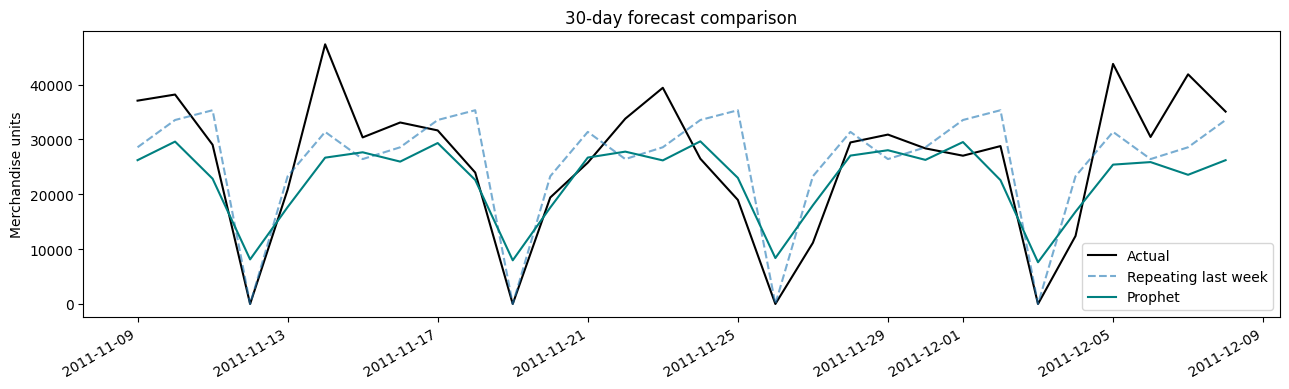

In [32]:
future_dates = pd.DataFrame({"ds": test.index})

prophet_output = prophet_model.predict(future_dates)

# Sales quantities cannot be negative.
prophet_prediction = pd.Series(
    prophet_output["yhat"].clip(lower=0).to_numpy(),
    index=test.index,
    name="Prophet",
)

prophet_comparison = pd.DataFrame({
    "Repeating last week": forecast_metrics(test["Units"], baseline),
    "Four-week weekday average": forecast_metrics(
        test["Units"], weekday_forecast
    ),
    "Prophet": forecast_metrics(test["Units"], prophet_prediction),
}).T

display(prophet_comparison.round(2))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test.index, test["Units"], label="Actual", color="black")
ax.plot(test.index, baseline, "--", label="Repeating last week", alpha=0.6)
ax.plot(test.index, prophet_prediction, label="Prophet", color="teal")

ax.set_title("30-day forecast comparison")
ax.set_ylabel("Merchandise units")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [33]:
prophet_validation_rows = []

for offset in [90, 60, 30]:
    end = len(daily_sales) - offset
    start = end - 30

    history = daily_sales.iloc[:start]
    validation = daily_sales.iloc[start:end]

    print(
        f"Validating {validation.index.min().date()} "
        f"to {validation.index.max().date()}...",
        flush=True,
    )

    fit_data = pd.DataFrame({
        "ds": history.index,
        "y": history["Units"].to_numpy(),
    })

    model = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False,
        uncertainty_samples=0,
    )
    model.fit(fit_data)

    predictions = model.predict(
        pd.DataFrame({"ds": validation.index})
    )["yhat"].clip(lower=0).to_numpy()

    prophet_validation_rows.append({
        "Model": "Prophet",
        "ValidationStart": validation.index.min().date(),
        "ValidationEnd": validation.index.max().date(),
        **forecast_metrics(validation["Units"], predictions),
    })

# Remove any previous Prophet results so rerunning won't duplicate them.
all_validation = pd.concat(
    [
        validation_results.loc[
            validation_results["Model"].ne("Prophet")
        ],
        pd.DataFrame(prophet_validation_rows),
    ],
    ignore_index=True,
)

model_summary = (
    all_validation.groupby("Model")
    .agg(
        Windows=("WAPE_pct", "size"),
        MeanMAE=("MAE", "mean"),
        MeanRMSE=("RMSE", "mean"),
        MeanWindowWAPE=("WAPE_pct", "mean"),
        WorstWindowWAPE=("WAPE_pct", "max"),
    )
    .sort_values("MeanWindowWAPE")
)

display(model_summary.round(2))

Validating 2011-08-11 to 2011-09-09...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
05:27:49 - cmdstanpy - INFO - Chain [1] start processing
05:27:49 - cmdstanpy - INFO - Chain [1] done processing


Validating 2011-09-10 to 2011-10-09...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
05:27:49 - cmdstanpy - INFO - Chain [1] start processing
05:27:50 - cmdstanpy - INFO - Chain [1] done processing


Validating 2011-10-10 to 2011-11-08...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
05:27:50 - cmdstanpy - INFO - Chain [1] start processing
05:27:50 - cmdstanpy - INFO - Chain [1] done processing


,Windows,MeanMAE,MeanRMSE,MeanWindowWAPE,WorstWindowWAPE
Model,,,,,
Four-week weekday average,3,6339.83,8497.11,35.16,40.66
Prophet,3,6433.34,7773.96,36.12,45.70
Repeating last week,3,7100.71,10437.00,38.88,41.75


In [34]:
print(model_summary.round(2).to_string())

                           Windows  MeanMAE  MeanRMSE  MeanWindowWAPE  WorstWindowWAPE
Model                                                                                 
Four-week weekday average        3  6339.83   8497.11           35.16            40.66
Prophet                          3  6433.34   7773.96           36.12            45.70
Repeating last week              3  7100.71  10437.00           38.88            41.75


In [35]:
recent_history = daily_sales.tail(28).copy()

weekday_means_final = recent_history.groupby(
    recent_history.index.dayofweek
)["Units"].mean()

future_dates = pd.date_range(
    start=daily_sales.index.max() + pd.Timedelta(days=1),
    periods=30,
    freq="D",
)

forecast_30d = pd.DataFrame({
    "Date": future_dates,
    "ForecastUnits": [
        weekday_means_final.loc[day]
        for day in future_dates.dayofweek
    ],
})

forecast_30d["Model"] = "Four-week weekday average"

print("Forecast starts:", forecast_30d["Date"].min().date())
print("Forecast ends:", forecast_30d["Date"].max().date())
print(
    "Forecast total units:",
    f"{forecast_30d['ForecastUnits'].sum():,.0f}",
)

display(forecast_30d.round({"ForecastUnits": 2}))

Forecast starts: 2011-12-09
Forecast ends: 2012-01-07
Forecast total units: 724,286


,Date,ForecastUnits,Model
0,2011-12-09,25179.50,Four-week weekday average
1,2011-12-10,0.00,Four-week weekday average
2,2011-12-11,15947.50,Four-week weekday average
3,2011-12-12,36568.50,Four-week weekday average
4,2011-12-13,31360.50,Four-week weekday average
5,2011-12-14,35672.00,Four-week weekday average
6,2011-12-15,30048.75,Four-week weekday average
7,2011-12-16,25179.50,Four-week weekday average
8,2011-12-17,0.00,Four-week weekday average
9,2011-12-18,15947.50,Four-week weekday average


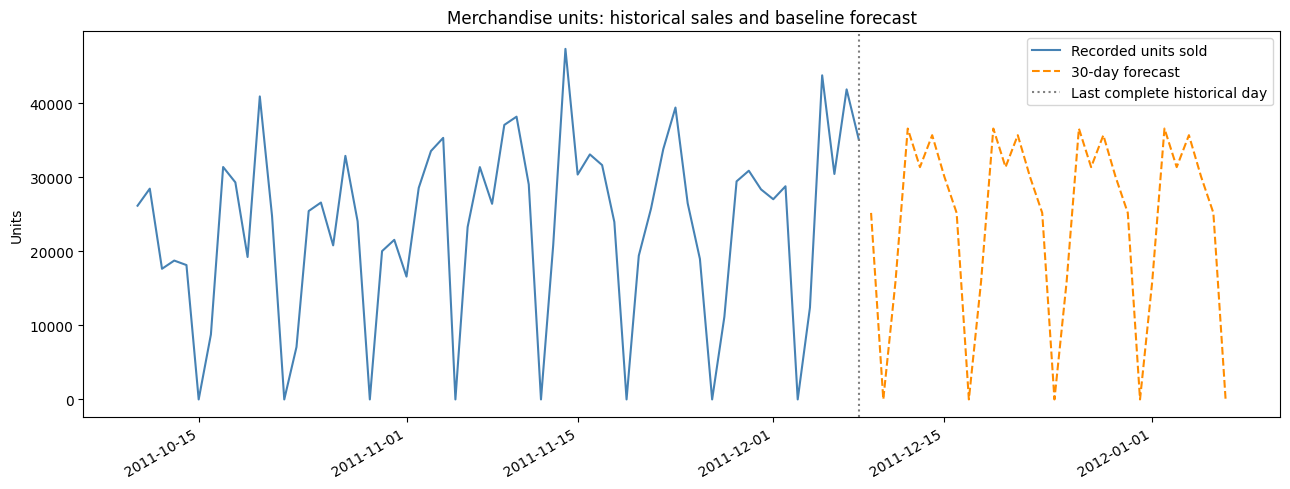

In [36]:
fig, ax = plt.subplots(figsize=(13, 5))

history_to_plot = daily_sales.tail(60)

ax.plot(
    history_to_plot.index,
    history_to_plot["Units"],
    label="Recorded units sold",
    color="steelblue",
)

ax.plot(
    forecast_30d["Date"],
    forecast_30d["ForecastUnits"],
    "--",
    label="30-day forecast",
    color="darkorange",
)

ax.axvline(
    daily_sales.index.max(),
    color="gray",
    linestyle=":",
    label="Last complete historical day",
)

ax.set_title("Merchandise units: historical sales and baseline forecast")
ax.set_ylabel("Units")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [37]:
def create_churn_snapshot(
    data,
    cutoff,
    complete_until,
    lookback_days=180,
    horizon_days=90,
):
    cutoff = pd.Timestamp(cutoff)
    complete_until = pd.Timestamp(complete_until)

    history_start = cutoff - pd.Timedelta(days=lookback_days)
    outcome_end = cutoff + pd.Timedelta(days=horizon_days)

    # complete_until is an exclusive boundary.
    if outcome_end > complete_until:
        raise ValueError("Not enough complete future data to label this snapshot.")

    if history_start < data["InvoiceDate"].min().normalize():
        raise ValueError("Not enough historical data for this snapshot.")

    history = data.loc[
        data["InvoiceDate"].ge(history_start)
        & data["InvoiceDate"].lt(cutoff)
    ].copy()

    future = data.loc[
        data["InvoiceDate"].ge(cutoff)
        & data["InvoiceDate"].lt(outcome_end)
    ]

    features = history.groupby("Customer ID").agg(
        LastPurchase=("InvoiceDate", "max"),
        FirstPurchaseInWindow=("InvoiceDate", "min"),
        Frequency=("Invoice", "nunique"),
        Monetary=("SalesValue", "sum"),
        Units=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
    )

    features["Recency"] = (
        cutoff - features["LastPurchase"].dt.normalize()
    ).dt.days

    features["ObservedSpanDays"] = (
        features["LastPurchase"].dt.normalize()
        - features["FirstPurchaseInWindow"].dt.normalize()
    ).dt.days

    features["AverageInvoiceValue"] = (
        features["Monetary"] / features["Frequency"]
    )

    returning_customers = future["Customer ID"].unique()

    # 1 = no purchase in the following 90 days; 0 = purchased again.
    features["Churn90"] = (
        ~features.index.isin(returning_customers)
    ).astype(int)

    features = features.drop(
        columns=["LastPurchase", "FirstPurchaseInWindow"]
    )

    features["SnapshotDate"] = cutoff
    features["OutcomeEnd"] = outcome_end

    return features.reset_index()

In [38]:
# Exclude the dataset's final, potentially incomplete day.
complete_until = merchandise["InvoiceDate"].max().normalize()

churn_train = create_churn_snapshot(
    customer_merchandise,
    cutoff="2011-03-01",
    complete_until=complete_until,
)

churn_test = create_churn_snapshot(
    customer_merchandise,
    cutoff="2011-09-01",
    complete_until=complete_until,
)

assert churn_train["OutcomeEnd"].max() <= churn_test["SnapshotDate"].min()

churn_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Customers": len(frame),
        "InactiveNext90Days": int(frame["Churn90"].sum()),
        "InactivityRatePct": frame["Churn90"].mean() * 100,
    }
    for name, frame in [
        ("Training", churn_train),
        ("Later evaluation", churn_test),
    ]
])

display(churn_summary.round(2))
display(churn_train.head())

,Dataset,Customers,InactiveNext90Days,InactivityRatePct
0,Training,3338,1924,57.64
1,Later evaluation,2768,1088,39.31


,Customer ID,Frequency,Monetary,Units,UniqueProducts,Recency,ObservedSpanDays,AverageInvoiceValue,Churn90,SnapshotDate,OutcomeEnd
0,12346,1,77183.60,74215,1,42,0,77183.60,1,2011-03-01,2011-05-30
1,12347,3,1798.71,1143,77,34,87,599.57,0,2011-03-01,2011-05-30
2,12348,3,1061.40,2220,20,35,120,353.80,0,2011-03-01,2011-05-30
3,12349,1,1152.62,518,54,124,0,1152.62,1,2011-03-01,2011-05-30
4,12350,1,294.40,196,16,27,0,294.40,1,2011-03-01,2011-05-30


In [39]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression

churn_features = [
    "Frequency",
    "Monetary",
    "Units",
    "UniqueProducts",
    "Recency",
    "ObservedSpanDays",
    "AverageInvoiceValue",
]

X_train_churn = churn_train[churn_features].astype(float)
X_test_churn = churn_test[churn_features].astype(float)

y_train_churn = churn_train["Churn90"]
y_test_churn = churn_test["Churn90"]

for frame in [X_train_churn, X_test_churn]:
    assert np.isfinite(frame.to_numpy()).all()
    assert frame.ge(0).all().all()

assert y_train_churn.nunique() == 2
assert y_test_churn.nunique() == 2

churn_model = Pipeline([
    ("log_transform", FunctionTransformer(np.log1p)),
    ("scale", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42,
    )),
])

churn_model.fit(X_train_churn, y_train_churn)

churn_probability = churn_model.predict_proba(X_test_churn)[:, 1]

print("Churn model trained successfully.")

Churn model trained successfully.


In [40]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

def top_20_precision(y_true, scores):
    y = np.asarray(y_true)
    scores = np.asarray(scores)

    count = max(1, int(np.ceil(len(y) * 0.20)))
    ranked = np.argsort(-scores, kind="stable")[:count]

    return y[ranked].mean()

evaluation_rate = y_test_churn.mean()

ranking_results = pd.DataFrame([
    {
        "Method": "Logistic regression",
        "ROC_AUC": roc_auc_score(y_test_churn, churn_probability),
        "AveragePrecision": average_precision_score(
            y_test_churn, churn_probability
        ),
        "PrecisionTop20": top_20_precision(
            y_test_churn, churn_probability
        ),
    },
    {
        "Method": "Recency benchmark",
        "ROC_AUC": roc_auc_score(
            y_test_churn, X_test_churn["Recency"]
        ),
        "AveragePrecision": average_precision_score(
            y_test_churn, X_test_churn["Recency"]
        ),
        "PrecisionTop20": top_20_precision(
            y_test_churn, X_test_churn["Recency"]
        ),
    },
]).set_index("Method")

ranking_results["LiftTop20"] = (
    ranking_results["PrecisionTop20"] / evaluation_rate
)

display(ranking_results.round(3))

# Use a fixed starting threshold; do not tune it on this evaluation set.
predicted_labels = (churn_probability >= 0.50).astype(int)

print("Classification metrics at threshold 0.50:")
print(
    f"Precision: "
    f"{precision_score(y_test_churn, predicted_labels, zero_division=0):.3f}"
)
print(
    f"Recall: "
    f"{recall_score(y_test_churn, predicted_labels, zero_division=0):.3f}"
)
print(
    f"F1: "
    f"{f1_score(y_test_churn, predicted_labels, zero_division=0):.3f}"
)

display(pd.DataFrame(
    confusion_matrix(y_test_churn, predicted_labels, labels=[0, 1]),
    index=["Actual purchased again", "Actual inactive"],
    columns=["Predicted purchased again", "Predicted inactive"],
))

,ROC_AUC,AveragePrecision,PrecisionTop20,LiftTop20
Method,,,,
Logistic regression,0.731,0.590,0.632,1.607
Recency benchmark,0.657,0.543,0.612,1.557


Classification metrics at threshold 0.50:
Precision: 0.513
Recall: 0.858
F1: 0.642


,Predicted purchased again,Predicted inactive
Actual purchased again,796,884
Actual inactive,155,933


In [41]:
coefficient_table = pd.DataFrame({
    "Feature": churn_features,
    "Coefficient": churn_model.named_steps["classifier"].coef_[0],
}).sort_values("Coefficient", ascending=False)

display(coefficient_table.round(3))

,Feature,Coefficient
1,Monetary,0.796
4,Recency,0.288
5,ObservedSpanDays,-0.045
3,UniqueProducts,-0.075
2,Units,-0.139
6,AverageInvoiceValue,-0.665
0,Frequency,-1.348


In [42]:
churn_risk_review = churn_test[
    ["Customer ID", "SnapshotDate"] + churn_features + ["Churn90"]
].copy()

churn_risk_review["ModelRiskScore"] = churn_probability
churn_risk_review["PredictedInactiveAt050"] = predicted_labels

churn_risk_review = (
    churn_risk_review
    .sort_values(
        "ModelRiskScore",
        ascending=False,
        kind="stable",
    )
    .reset_index(drop=True)
)

churn_risk_review["RiskRank"] = np.arange(
    1, len(churn_risk_review) + 1
)

top_count = int(np.ceil(len(churn_risk_review) * 0.20))

churn_risk_review["Top20Percent"] = (
    churn_risk_review["RiskRank"] <= top_count
)

print(f"Customers in highest-risk 20%: {top_count:,}")

display(
    churn_risk_review[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "ModelRiskScore",
            "Churn90",
            "Top20Percent",
        ]
    ].head(20).round(3)
)

Customers in highest-risk 20%: 554


,Customer ID,Recency,Frequency,Monetary,ModelRiskScore,Churn90,Top20Percent
0,16446,106,1,2.90,0.935,1,True
1,17816,170,1,5.10,0.933,0,True
2,17956,150,1,12.75,0.930,1,True
3,14285,77,1,5.90,0.924,0,True
4,15863,93,1,9.20,0.920,0,True
5,17102,162,1,25.50,0.920,1,True
6,17763,164,1,15.00,0.915,1,True
7,16257,77,1,21.95,0.909,1,True
8,16162,153,1,37.40,0.906,1,True
9,17580,153,1,47.70,0.901,1,True


In [43]:
inventory_cutoff = train.index.max() + pd.Timedelta(days=1)
selection_start = inventory_cutoff - pd.Timedelta(days=90)

selection_data = merchandise.loc[
    merchandise["InvoiceDate"].ge(selection_start)
    & merchandise["InvoiceDate"].lt(inventory_cutoff)
].copy()

selection_data["SaleDate"] = (
    selection_data["InvoiceDate"].dt.normalize()
)

product_candidates = (
    selection_data.groupby("StockCode")
    .agg(
        UnitsSold=("Quantity", "sum"),
        SellingDays=("SaleDate", "nunique"),
        Invoices=("Invoice", "nunique"),
    )
)

# Prototype rule: sold on at least 20 distinct days in the last 90 days.
selected_products = (
    product_candidates.loc[
        product_candidates["SellingDays"].ge(20)
    ]
    .sort_values("UnitsSold", ascending=False)
    .head(20)
)

assert not selected_products.empty, "No products meet the selection rule."

display(selected_products)
print(f"Selected products: {len(selected_products)}")

,UnitsSold,SellingDays,Invoices
StockCode,,,
22197,15616,76,376
84077,14961,66,159
85099B,14350,76,581
23084,11932,44,265
21915,10454,69,278
84879,9233,76,391
22952,8997,69,287
21212,8964,74,330
22492,8428,61,116


Selected products: 20


In [44]:
selected_codes = selected_products.index

product_rows = merchandise.loc[
    merchandise["StockCode"].isin(selected_codes)
    & merchandise["InvoiceDate"].lt(
        daily_sales.index.max() + pd.Timedelta(days=1)
    )
].copy()

product_rows["Date"] = product_rows["InvoiceDate"].dt.normalize()

product_daily = (
    product_rows.groupby(["Date", "StockCode"])["Quantity"]
    .sum()
    .unstack("StockCode")
    .reindex(
        index=daily_sales.index,
        columns=selected_codes,
    )
    .fillna(0)
)

product_validation = []
product_test_predictions = {}

for code in selected_codes:
    history = product_daily.loc[train.index, code]
    actual = product_daily.loc[test.index, code]

    recent = history.tail(28)
    weekday_mean = recent.groupby(recent.index.dayofweek).mean()

    predicted = np.array([
        weekday_mean.loc[day]
        for day in actual.index.dayofweek
    ])

    product_test_predictions[code] = predicted

    product_validation.append({
        "StockCode": code,
        "ActualUnits": actual.sum(),
        "ForecastUnits": predicted.sum(),
        **forecast_metrics(actual, predicted),
    })

product_validation = pd.DataFrame(product_validation)

display(
    product_validation
    .sort_values("WAPE_pct")
    .round(2)
)

,StockCode,ActualUnits,ForecastUnits,MAE,RMSE,WAPE_pct
10,22086,7552.0,4766.00,131.03,180.50,52.05
14,23310,2309.0,2118.50,42.83,59.58,55.65
3,23084,15535.0,10723.25,291.23,607.18,56.24
17,23344,3885.0,3223.00,80.27,117.98,61.98
6,22952,4035.0,4350.00,89.65,114.79,66.65
5,84879,5624.0,3229.25,126.54,252.46,67.50
2,85099B,5736.0,3913.00,136.20,234.07,71.23
9,23203,3769.0,2062.00,94.30,191.12,75.06
13,20971,1387.0,1040.75,34.91,66.60,75.50
0,22197,15317.0,8101.75,391.56,693.29,76.69


In [45]:
lead_time_days = 7
review_period_days = 7
buffer_pct = 0.20

protection_days = lead_time_days + review_period_days

planning_dates = pd.date_range(
    start=product_daily.index.max() + pd.Timedelta(days=1),
    periods=protection_days,
    freq="D",
)

inventory_rows = []

for code in selected_codes:
    recent = product_daily[code].tail(28)
    weekday_mean = recent.groupby(recent.index.dayofweek).mean()

    predicted_units = np.array([
        weekday_mean.loc[day]
        for day in planning_dates.dayofweek
    ])

    lead_time_forecast = predicted_units[:lead_time_days].sum()
    protection_forecast = predicted_units.sum()
    buffer_units = protection_forecast * buffer_pct

    inventory_rows.append({
        "StockCode": code,
        "LeadTimeDays": lead_time_days,
        "ReviewPeriodDays": review_period_days,
        "LeadTimeForecastUnits": lead_time_forecast,
        "ProtectionPeriodForecastUnits": protection_forecast,
        "BufferUnits": buffer_units,
        "TargetInventoryPosition": int(
            np.ceil(protection_forecast + buffer_units)
        ),
    })

inventory_plan = pd.DataFrame(inventory_rows).set_index("StockCode")

# Unknown inventory inputs must not silently become zero.
for column in ["StockOnHand", "OnOrder", "Backorders"]:
    inventory_plan[column] = np.nan

display(inventory_plan.round(2))

,LeadTimeDays,ReviewPeriodDays,LeadTimeForecastUnits,ProtectionPeriodForecastUnits,BufferUnits,TargetInventoryPosition,StockOnHand,OnOrder,Backorders
StockCode,,,,,,,,,
22197,7,7,3474.75,6949.5,1389.9,8340,NaN,NaN,NaN
84077,7,7,1048.00,2096.0,419.2,2516,NaN,NaN,NaN
85099B,7,7,984.25,1968.5,393.7,2363,NaN,NaN,NaN
23084,7,7,3673.25,7346.5,1469.3,8816,NaN,NaN,NaN
21915,7,7,375.25,750.5,150.1,901,NaN,NaN,NaN
84879,7,7,1028.00,2056.0,411.2,2468,NaN,NaN,NaN
22952,7,7,919.50,1839.0,367.8,2207,NaN,NaN,NaN
21212,7,7,468.00,936.0,187.2,1124,NaN,NaN,NaN
22492,7,7,419.00,838.0,167.6,1006,NaN,NaN,NaN


In [46]:
def calculate_reorder_quantities(plan):
    result = plan.copy()
    input_columns = ["StockOnHand", "OnOrder", "Backorders"]

    inputs = result[input_columns]
    complete = inputs.notna().all(axis=1)

    if (inputs.lt(0) & inputs.notna()).any().any():
        raise ValueError("Inventory inputs must be non-negative.")

    result["InventoryPosition"] = (
        result["StockOnHand"]
        + result["OnOrder"]
        - result["Backorders"]
    )

    result["SuggestedOrderUnits"] = np.nan

    result.loc[complete, "SuggestedOrderUnits"] = np.ceil(
        (
            result.loc[complete, "TargetInventoryPosition"]
            - result.loc[complete, "InventoryPosition"]
        ).clip(lower=0)
    )

    result["Status"] = np.where(
        complete,
        "Scenario calculated",
        "Missing inventory inputs",
    )

    return result

inventory_plan = calculate_reorder_quantities(inventory_plan)

display(
    inventory_plan[
        [
            "TargetInventoryPosition",
            "StockOnHand",
            "OnOrder",
            "Backorders",
            "SuggestedOrderUnits",
            "Status",
        ]
    ]
)

,TargetInventoryPosition,StockOnHand,OnOrder,Backorders,SuggestedOrderUnits,Status
StockCode,,,,,,
22197,8340,NaN,NaN,NaN,NaN,Missing inventory inputs
84077,2516,NaN,NaN,NaN,NaN,Missing inventory inputs
85099B,2363,NaN,NaN,NaN,NaN,Missing inventory inputs
23084,8816,NaN,NaN,NaN,NaN,Missing inventory inputs
21915,901,NaN,NaN,NaN,NaN,Missing inventory inputs
84879,2468,NaN,NaN,NaN,NaN,Missing inventory inputs
22952,2207,NaN,NaN,NaN,NaN,Missing inventory inputs
21212,1124,NaN,NaN,NaN,NaN,Missing inventory inputs
22492,1006,NaN,NaN,NaN,NaN,Missing inventory inputs


In [47]:
from pathlib import Path
import json

OUTPUT_DIR = ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

exports = {
    "daily_sales.csv": daily_sales.reset_index(),
    "customer_segments.csv": rfm_clustered.reset_index(),
    "segment_summary.csv": segment_summary.reset_index(),
    "sales_forecast.csv": forecast_30d,
    "forecast_validation.csv": all_validation,
    "churn_evaluation.csv": churn_risk_review,
    "churn_metrics.csv": ranking_results.reset_index(),
    "inventory_scenarios.csv": inventory_plan.reset_index(),
    "product_forecast_validation.csv": product_validation,
}

for filename, dataframe in exports.items():
    dataframe.to_csv(OUTPUT_DIR / filename, index=False)
    print(f"Saved {filename}: {len(dataframe):,} rows")

metadata = {
    "dataset": "Online Retail II",
    "currency": "GBP",
    "last_complete_sales_date": str(daily_sales.index.max().date()),
    "forecast_model": "Four-week weekday average",
    "forecast_start": str(forecast_30d["Date"].min().date()),
    "forecast_end": str(forecast_30d["Date"].max().date()),
    "segmentation_status": "Provisional two-cluster model",
    "churn_prediction_date": "2011-09-01",
    "churn_definition": "No merchandise purchase in the following 90 days",
    "inventory_assumptions": {
        "lead_time_days": lead_time_days,
        "review_period_days": review_period_days,
        "buffer_fraction": buffer_pct,
    },
    "limitations": [
        "Historical analytics, not live data.",
        "Sales values are gross merchandise purchases before returns.",
        "Within-sheet duplicate candidates were retained.",
        "Days without recorded purchases were treated as zero sales.",
        "Churn scores are historical and have not been calibrated.",
        "Inventory outputs are scenarios, not validated ordering advice.",
        "Stock-on-hand, incoming orders and backorders are unknown unless supplied.",
    ],
}

with open(OUTPUT_DIR / "metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print(f"\nOutput folder: {OUTPUT_DIR.resolve()}")

Saved daily_sales.csv: 738 rows
Saved customer_segments.csv: 4,261 rows
Saved segment_summary.csv: 2 rows
Saved sales_forecast.csv: 30 rows
Saved forecast_validation.csv: 9 rows
Saved churn_evaluation.csv: 2,768 rows
Saved churn_metrics.csv: 2 rows
Saved inventory_scenarios.csv: 20 rows
Saved product_forecast_validation.csv: 20 rows

Output folder: C:\Users\crawlo\OneDrive - MORNINGSTAR INC\Documents\Chiranjeevi\RetailPulse\data\processed


In [48]:
for filename, original in exports.items():
    saved = pd.read_csv(
        OUTPUT_DIR / filename,
        dtype={"Customer ID": "string", "StockCode": "string"},
    )
    assert len(saved) == len(original), f"Row-count mismatch: {filename}"
    assert saved.columns.tolist() == original.columns.tolist(), (
        f"Column mismatch: {filename}"
    )

print("All 9 CSV files passed row-count and column checks.")
print("Metadata saved:", (OUTPUT_DIR / "metadata.json").exists())

All 9 CSV files passed row-count and column checks.
Metadata saved: True


In [49]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [50]:
app_code = '''
from pathlib import Path
import json
import numpy as np
import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="RetailPulse",
    page_icon="📊",
    layout="wide",
)

DATA = Path(__file__).resolve().parent / "data" / "processed"

if not (DATA / "metadata.json").exists():
    st.error(f"Processed data not found in {DATA}")
    st.stop()

def load_csv(name):
    return pd.read_csv(
        DATA / name,
        dtype={"Customer ID": "string", "StockCode": "string"},
    )

metadata = json.loads(
    (DATA / "metadata.json").read_text(encoding="utf-8")
)

st.title("RetailPulse")
st.caption("Customer analytics and demand forecasting")
st.info(
    "Historical Online Retail II analysis. "
    "Sales are gross merchandise purchases before returns."
)

sales_tab, segments_tab, forecast_tab, churn_tab, inventory_tab = st.tabs(
    ["Sales", "Customer segments", "Forecasts", "Churn evaluation", "Inventory"]
)

with sales_tab:
    st.subheader("Sales overview")
    daily = load_csv("daily_sales.csv")
    daily["Date"] = pd.to_datetime(daily["Date"])

    start, end = st.slider(
        "Date range",
        min_value=daily["Date"].min().date(),
        max_value=daily["Date"].max().date(),
        value=(
            daily["Date"].min().date(),
            daily["Date"].max().date(),
        ),
    )

    selected = daily.loc[
        daily["Date"].dt.date.between(start, end)
    ]

    a, b, c = st.columns(3)
    a.metric("Gross merchandise value", f"£{selected['GrossSales'].sum():,.0f}")
    b.metric("Units sold", f"{selected['Units'].sum():,.0f}")
    c.metric("Days shown", len(selected))

    measure = st.selectbox("Chart measure", ["GrossSales", "Units", "Invoices"])
    st.line_chart(selected.set_index("Date")[[measure]])

with segments_tab:
    st.subheader("Customer segments")
    st.caption(
        "Provisional two-cluster segmentation of customers purchasing "
        "within the final 365-day analysis window."
    )
    summary = load_csv("segment_summary.csv")
    customers = load_csv("customer_segments.csv")

    st.bar_chart(summary.set_index("Segment")[["Customers"]])
    st.dataframe(summary, hide_index=True)

    segment = st.selectbox(
        "View customers in segment",
        customers["Segment"].dropna().unique().tolist(),
    )
    st.dataframe(
        customers.loc[customers["Segment"].eq(segment)],
        hide_index=True,
    )

with forecast_tab:
    st.subheader("30-day historical forecast")
    st.caption(
        f"Model: {metadata['forecast_model']}. "
        "No explicit Christmas or New Year adjustment."
    )

    forecast = load_csv("sales_forecast.csv")
    forecast["Date"] = pd.to_datetime(forecast["Date"])

    st.line_chart(forecast.set_index("Date")[["ForecastUnits"]])
    st.dataframe(forecast, hide_index=True)

    st.write("Earlier validation windows")
    st.dataframe(load_csv("forecast_validation.csv"), hide_index=True)

    st.download_button(
        "Download forecast",
        forecast.to_csv(index=False).encode("utf-8"),
        file_name="sales_forecast.csv",
        mime="text/csv",
    )

with churn_tab:
    st.subheader("Historical churn evaluation")
    st.caption(
        "Predictions as of 1 September 2011. Target: no merchandise "
        "purchase in the next 90 days. Scores are not calibrated probabilities."
    )

    st.dataframe(load_csv("churn_metrics.csv"), hide_index=True)

    risks = load_csv("churn_evaluation.csv")
    top_only = st.checkbox("Show highest-risk 20% only", value=True)

    if top_only:
        risks = risks.loc[
            risks["Top20Percent"].astype(str).str.lower().eq("true")
        ]

    st.dataframe(
        risks.sort_values("ModelRiskScore", ascending=False),
        hide_index=True,
    )

with inventory_tab:
    st.subheader("Inventory planning scenario")
    assumptions = metadata["inventory_assumptions"]
    st.caption(
        f"Assumed lead time: {assumptions['lead_time_days']} days. "
        f"Review interval: {assumptions['review_period_days']} days. "
        f"Illustrative buffer: {assumptions['buffer_fraction']:.0%}. "
        "Incoming orders are assumed to arrive within the planning period."
    )
    st.warning(
        "Enter stock inputs to calculate scenario orders. "
        "Blank inputs remain unknown. Edits are temporary unless downloaded."
    )

    inventory = load_csv("inventory_scenarios.csv")
    inputs = ["StockOnHand", "OnOrder", "Backorders"]

    # Hide previously calculated fields so edits cannot show stale results.
    base = inventory.drop(
        columns=["InventoryPosition", "SuggestedOrderUnits", "Status"],
        errors="ignore",
    )

    edited = st.data_editor(
        base,
        disabled=[column for column in base.columns if column not in inputs],
        column_config={
            column: st.column_config.NumberColumn(column, min_value=0.0)
            for column in inputs
        },
        hide_index=True,
        key="inventory_editor",
    )

    values = edited[inputs]
    valid = (
        values.notna().all(axis=1)
        & values.ge(0).all(axis=1)
        & np.isfinite(values).all(axis=1)
    )

    result = edited.copy()
    result["InventoryPosition"] = (
        result["StockOnHand"] + result["OnOrder"] - result["Backorders"]
    )
    result["SuggestedOrderUnits"] = np.nan
    result.loc[valid, "SuggestedOrderUnits"] = np.ceil(
        (
            result.loc[valid, "TargetInventoryPosition"]
            - result.loc[valid, "InventoryPosition"]
        ).clip(lower=0)
    )
    result["Status"] = np.where(
        valid, "Scenario calculated", "Missing or invalid stock inputs"
    )

    st.dataframe(
        result[["StockCode", "SuggestedOrderUnits", "Status"]],
        hide_index=True,
    )

    st.download_button(
        "Download inventory scenario",
        result.to_csv(index=False).encode("utf-8"),
        file_name="inventory_scenario.csv",
        mime="text/csv",
    )

    with st.expander("Product forecast validation"):
        st.dataframe(
            load_csv("product_forecast_validation.csv"),
            hide_index=True,
        )

with st.expander("Data limitations"):
    for limitation in metadata["limitations"]:
        st.write("- " + limitation)
'''

APP_PATH = ROOT / "app.py"
APP_PATH.write_text(app_code, encoding="utf-8")

# Check Python syntax before launching.
compile(app_code, str(APP_PATH), "exec")
print("Dashboard created:", APP_PATH.resolve())
print("Python syntax check passed.")

Dashboard created: C:\Users\crawlo\OneDrive - MORNINGSTAR INC\Documents\Chiranjeevi\RetailPulse\app.py
Python syntax check passed.


In [51]:
import sys

print(f'"{sys.executable}" -m streamlit run "{APP_PATH.resolve()}"')

"C:\Users\crawlo\AppData\Local\Programs\Python\Python313\python.exe" -m streamlit run "C:\Users\crawlo\OneDrive - MORNINGSTAR INC\Documents\Chiranjeevi\RetailPulse\app.py"


In [52]:
"C:\Users\crawlo\AppData\Local\Programs\Python\Python313\python.exe" -m streamlit run "C:\Users\crawlo\OneDrive - MORNINGSTAR INC\Documents\Chiranjeevi\RetailPulse\app.py"


SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (803747181.py, line 1)

In [53]:
with st.sidebar:
    st.title("📊 RetailPulse")
    st.caption("Customer Analytics & Demand Forecasting")

    st.divider()

    page = st.radio(
        "Navigation",
        [
            "Sales Overview",
            "Customer Segments",
            "Demand Forecasting",
            "Churn Analysis",
            "Inventory Planning",
        ],
        label_visibility="collapsed",
    )

    st.divider()
    st.caption("Dataset: Online Retail II")
    st.caption("Historical analysis · GBP")

NameError: name 'st' is not defined

In [54]:
---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
Cell In[53], line 1
----> 1 with st.sidebar:
      2     st.title("📊 RetailPulse")
      3     st.caption("Customer Analytics & Demand Forecasting")
      4 

NameError: name 'st' is not defined

SyntaxError: invalid syntax (1555057498.py, line 1)

In [55]:
from pathlib import Path
from datetime import datetime

app_path = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse\app.py"
)

if "app_code" not in globals():
    raise RuntimeError(
        "Original app_code is unavailable. Rerun Cell 41 "
        "(the complete dashboard creation cell), then run this cell again."
    )

# Restore from the original dashboard code held in the notebook.
restored = app_code

old_navigation = '''sales_tab, segments_tab, forecast_tab, churn_tab, inventory_tab = st.tabs(
    ["Sales", "Customer segments", "Forecasts", "Churn evaluation", "Inventory"]
)'''

new_navigation = '''with st.sidebar:
    st.title("📊 RetailPulse")
    st.caption("Customer Analytics & Demand Forecasting")

    page = st.radio(
        "Navigation",
        [
            "Sales Overview",
            "Customer Segments",
            "Demand Forecasting",
            "Churn Analysis",
            "Inventory Planning",
        ],
    )

    st.divider()
    st.caption("Historical Online Retail II analysis · GBP")
'''

changes = {
    old_navigation: new_navigation,
    "with sales_tab:": 'if page == "Sales Overview":',
    "with segments_tab:": 'elif page == "Customer Segments":',
    "with forecast_tab:": 'elif page == "Demand Forecasting":',
    "with churn_tab:": 'elif page == "Churn Analysis":',
    "with inventory_tab:": 'elif page == "Inventory Planning":',
}

for old, new in changes.items():
    if restored.count(old) != 1:
        raise ValueError(
            "Original template does not match. "
            "No file changed. Please upload your app.py."
        )
    restored = restored.replace(old, new, 1)

# Validate before replacing the file.
compile(restored, str(app_path), "exec")

# Preserve the current file for recovery.
if app_path.exists():
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup = app_path.with_name(f"app_backup_{timestamp}.txt")
    backup.write_bytes(app_path.read_bytes())

app_path.write_text(restored, encoding="utf-8")
print("Dashboard restored with left sidebar navigation.")

Dashboard restored with left sidebar navigation.


In [56]:
from pathlib import Path
from datetime import datetime

app_path = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse\app.py"
)

code = app_path.read_text(encoding="utf-8")

style_block = '''
# RETAILPULSE_STYLE_START
st.markdown("""
<style>
.stApp {
    background: #f4f7fb;
    color: #16243a;
}

.block-container {
    max-width: 1450px;
    padding-top: 2rem;
    padding-bottom: 3rem;
}

[data-testid="stSidebar"] {
    background: #102438;
}
[data-testid="stSidebar"] h1,
[data-testid="stSidebar"] h2,
[data-testid="stSidebar"] p,
[data-testid="stSidebar"] label,
[data-testid="stSidebar"] span {
    color: #edf5fc !important;
}
[data-testid="stSidebar"] hr {
    border-color: #355069;
}
[data-testid="stSidebar"] [role="radiogroup"] {
    gap: 0.65rem;
}
[data-testid="stSidebar"] [role="radiogroup"] > label {
    background: #19364d;
    border: 1px solid #2b4b62;
    border-radius: 10px;
    padding: 12px 14px;
}
[data-testid="stSidebar"] [role="radiogroup"] > label:hover {
    background: #24516a;
}

[data-testid="stMetric"] {
    background: white;
    border: 1px solid #dce5ee;
    border-top: 4px solid #0f9488;
    border-radius: 14px;
    padding: 20px;
    box-shadow: 0 4px 14px rgba(16, 36, 56, 0.05);
}
[data-testid="stMetricValue"] {
    color: #102438;
    font-weight: 700;
}
[data-testid="stMetricLabel"] {
    color: #52657a;
}

.stButton > button,
.stDownloadButton > button {
    background: #0f766e;
    color: white;
    border: 0;
    border-radius: 9px;
    padding: 0.65rem 1rem;
}
.stButton > button:hover,
.stDownloadButton > button:hover {
    background: #115e59;
    color: white;
}
.stButton > button:focus-visible,
.stDownloadButton > button:focus-visible {
    outline: 3px solid #f59e0b;
    outline-offset: 3px;
}

.rp-hero {
    background: linear-gradient(115deg, #102438, #145b65);
    padding: 30px 34px;
    border-radius: 18px;
    margin-bottom: 24px;
}
.rp-eyebrow {
    color: #9de5dc;
    font-size: 12px;
    font-weight: 700;
    letter-spacing: 2px;
    margin-bottom: 10px;
}
.rp-title {
    color: white;
    font-size: clamp(30px, 5vw, 44px);
    font-weight: 750;
    margin: 0;
    line-height: 1.2;
}
.rp-subtitle {
    color: #d6e8f0;
    font-size: 16px;
    margin-top: 12px;
}
.rp-badge {
    display: inline-block;
    background: #244b60;
    color: #e3f2f8;
    padding: 6px 12px;
    border-radius: 20px;
    font-size: 12px;
    margin-top: 16px;
}
</style>
""", unsafe_allow_html=True)
# RETAILPULSE_STYLE_END
'''

hero = '''
st.markdown("""
<div class="rp-hero">
    <div class="rp-eyebrow">RETAIL ANALYTICS</div>
    <h1 class="rp-title">RetailPulse</h1>
    <div class="rp-subtitle">
        Explore sales, understand customers, and plan inventory.
    </div>
    <div class="rp-badge">Online Retail II · Historical analysis · GBP</div>
</div>
""", unsafe_allow_html=True)
'''

# Update an existing style block if you rerun this cell.
start_marker = "# RETAILPULSE_STYLE_START"
end_marker = "# RETAILPULSE_STYLE_END"

if start_marker in code and end_marker in code:
    start = code.index(start_marker)
    end = code.index(end_marker) + len(end_marker)
    updated = code[:start] + style_block.strip() + code[end:]
else:
    anchor = 'DATA = Path(__file__).resolve().parent / "data" / "processed"'
    if anchor not in code:
        raise ValueError(
            "Dashboard structure differs. No changes made. "
            "Please share your current app.py."
        )
    updated = code.replace(anchor, style_block + "\n" + anchor, 1)

old_header = (
    'st.title("RetailPulse")\n'
    'st.caption("Customer analytics and demand forecasting")'
)
if old_header in updated:
    updated = updated.replace(old_header, hero, 1)

# Check syntax before writing.
compile(updated, str(app_path), "exec")

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
backup = app_path.with_name(f"app_before_design_{timestamp}.txt")
backup.write_text(code, encoding="utf-8")
app_path.write_text(updated, encoding="utf-8")

print("Dashboard design updated.")
print("Backup saved:", backup.name)
print("Refresh http://localhost:8501")

Dashboard design updated.
Backup saved: app_before_design_20261028_054614_982892.txt
Refresh http://localhost:8501


In [57]:
from pathlib import Path
from datetime import datetime

app_path = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse\app.py"
)

code = app_path.read_text(encoding="utf-8")

css_fix = """
/* RETAILPULSE_CONTRAST_FIX */
.rp-hero h1.rp-title {
    color: #ffffff !important;
    margin: 0 !important;
    padding: 0 !important;
}
.block-container {
    padding-top: 5rem !important;
}
"""

if "/* RETAILPULSE_CONTRAST_FIX */" not in code:
    if "</style>" not in code:
        raise ValueError("Style block not found. No changes made.")

    updated = code.replace("</style>", css_fix + "\n</style>", 1)
    compile(updated, str(app_path), "exec")

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup = app_path.with_name(f"app_before_contrast_{timestamp}.txt")
    backup.write_text(code, encoding="utf-8")
    app_path.write_text(updated, encoding="utf-8")

    print("Title contrast and header spacing fixed.")
else:
    print("Contrast fix already applied.")

Title contrast and header spacing fixed.


In [58]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime
import sys

PROJECT = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse"
)

assert (PROJECT / "app.py").exists(), "app.py was not found."

# Pin the installed versions used by the dashboard.
# Model training dependencies will be documented separately.
requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in ["streamlit", "pandas", "numpy"]
) + "\n"

gitignore = """# Python and environments
__pycache__/
*.py[cod]
.venv/
venv/
env/

# Notebook checkpoints
.ipynb_checkpoints/

# Secrets and local settings
.env
.env.*
!.env.example
.streamlit/secrets.toml

# Raw datasets and large training artifacts
data/raw/
*.xlsx
*.xls
*.zip
models/
mlruns/
mlartifacts/

# Local backups
app_backup_*.txt
app_before_*.txt
app_before_sidebar.py
*.backup-*

# OS files
.DS_Store
Thumbs.db

# Small processed CSV files and metadata are intentionally included:
# the dashboard needs data/processed/ to run.
"""

readme = '''# RetailPulse

A retail analytics portfolio project built with Python and Streamlit,
using the historical Online Retail II dataset.

## Current features

- Sales overview with date filtering
- Provisional RFM customer segmentation
- Aggregate 30-day sales-unit forecasts
- Historical 90-day customer inactivity evaluation
- Product-level inventory scenarios with editable stock inputs
- Forecast and inventory CSV downloads

This is a local prototype. Public deployment and production MLOps
have not yet been completed.

## Project structure

```text
RetailPulse/
    app.py
    requirements.txt
    .gitignore
    README.md
    notebooks/
    data/
        processed/
            daily_sales.csv
            customer_segments.csv
            segment_summary.csv
            sales_forecast.csv
            forecast_validation.csv
            churn_evaluation.csv
            churn_metrics.csv
            inventory_scenarios.csv
            product_forecast_validation.csv
            metadata.json

_IncompleteInputError: incomplete input (4230542169.py, line 59)

In [59]:
from pathlib import Path
from datetime import datetime

PROJECT = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse"
)

required_variables = ["requirements", "gitignore", "readme"]
missing = [name for name in required_variables if name not in globals()]

if missing:
    print("Missing variables:", ", ".join(missing))
    print(
        "Rerun the earlier cell that defines requirements, gitignore, "
        "and readme, then run this cell again."
    )
else:
    PROJECT.mkdir(parents=True, exist_ok=True)

    files = {
        "requirements.txt": requirements,
        ".gitignore": gitignore,
        "README.md": readme,
    }

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

    for filename, content in files.items():
        path = PROJECT / filename

        if path.exists():
            backup = path.with_name(f"{filename}.backup-{timestamp}")
            backup.write_bytes(path.read_bytes())

        path.write_text(content, encoding="utf-8")

        print(f"Saved: {path}")
        print(f"File size: {path.stat().st_size:,} bytes\n")

Missing variables: requirements, gitignore, readme
Rerun the earlier cell that defines requirements, gitignore, and readme, then run this cell again.


In [60]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime

PROJECT = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse"
)

if not (PROJECT / "app.py").exists():
    raise FileNotFoundError(f"app.py not found inside: {PROJECT}")

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in ["streamlit", "pandas", "numpy"]
) + "\n"

gitignore = """# Python environments and caches
.venv/
venv/
env/
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Secrets
.env
.env.*
!.env.example
.streamlit/secrets.toml

# Raw datasets and training artifacts
data/raw/
*.xlsx
*.xls
*.zip
models/
mlruns/
mlartifacts/

# Local backups
app_backup_*.txt
app_before_*.txt
app_before_sidebar.py
*.backup-*

# Operating system files
.DS_Store
Thumbs.db

# Keep data/processed/ tracked: the dashboard requires these files.
"""

readme = r"""# RetailPulse

Customer analytics and demand forecasting using historical
Online Retail II transaction data.

## Features

- Sales overview with date filtering
- Provisional RFM customer segmentation
- Historical 30-day sales-unit forecasts
- Historical customer inactivity risk evaluation
- Inventory planning scenarios with editable stock inputs
- CSV downloads

## Current status

Local Streamlit prototype. Public deployment, advanced modeling,
and production MLOps are not complete.

## Required files

Keep these files together:

- app.py
- requirements.txt
- README.md
- data/processed/ containing all nine exported CSV files and metadata.json

## Run on Windows

Open Command Prompt in the RetailPulse folder:

```bat
py -3.13 -m venv .venv
.venv\Scripts\activate
python -m pip install -r requirements.txt
python -m streamlit run app.py --theme.base=light --theme.primaryColor="#0f9488" --theme.backgroundColor="#f4f7fb" --theme.secondaryBackgroundColor="#ffffff" --theme.textColor="#16243a"

_IncompleteInputError: incomplete input (920122358.py, line 54)

In [61]:
from pathlib import Path
from datetime import datetime
from importlib.metadata import version

PROJECT = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse"
)

assert (PROJECT / "app.py").exists(), "Check your RetailPulse folder path."

def save_file(name, content):
    path = PROJECT / name

    if path.exists():
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
        path.with_name(f"{name}.backup-{stamp}").write_bytes(
            path.read_bytes()
        )

    path.write_text(content, encoding="utf-8")
    print(f"Saved: {path.name} — {path.stat().st_size:,} bytes")

In [62]:
packages = ["streamlit", "pandas", "numpy"]

save_file(
    "requirements.txt",
    "\n".join(f"{p}=={version(p)}" for p in packages) + "\n"
)

Saved: requirements.txt — 48 bytes


In [63]:
ignore_lines = [
    ".venv/",
    "venv/",
    "env/",
    "__pycache__/",
    "*.py[cod]",
    ".ipynb_checkpoints/",
    ".env",
    ".env.*",
    "!.env.example",
    ".streamlit/secrets.toml",
    "data/raw/",
    "*.xlsx",
    "*.xls",
    "*.zip",
    "models/",
    "mlruns/",
    "mlartifacts/",
    "app_backup_*.txt",
    "app_before_*.txt",
    "app_before_sidebar.py",
    "*.backup-*",
    ".DS_Store",
    "Thumbs.db",
]

save_file(".gitignore", "\n".join(ignore_lines) + "\n")

Saved: .gitignore — 279 bytes


In [64]:
readme_lines = [
    "# RetailPulse",
    "",
    "Historical retail analytics using Online Retail II and Streamlit.",
    "",
    "## Features",
    "- Sales overview and date filtering",
    "- Provisional RFM customer segmentation",
    "- Historical 30-day sales-unit forecasting",
    "- Historical 90-day customer inactivity evaluation",
    "- Inventory scenarios and CSV downloads",
    "",
    "## Setup",
    "Open Command Prompt inside the RetailPulse folder.",
    "Run these commands:",
    "",
    "    py -3.13 -m venv .venv",
    r"    .venv\Scripts\activate",
    "    python -m pip install -r requirements.txt",
    '    python -m streamlit run app.py --theme.base=light --theme.primaryColor="#0f9488" --theme.backgroundColor="#f4f7fb" --theme.secondaryBackgroundColor="#ffffff" --theme.textColor="#16243a"',
    "",
    "Open http://localhost:8501 and keep the terminal running.",
    "",
    "## Required data",
    "Keep all nine exported CSV files and metadata.json in data/processed/.",
    "The dashboard reads these files without retraining models.",
    "requirements.txt covers dashboard dependencies only.",
    "",
    "## Current results",
    "- Four-week weekday-average forecast: mean validation WAPE 35.16%.",
    "- Churn logistic regression ROC-AUC: 0.731.",
    "- Churn precision among highest-risk 20%: 0.632.",
    "- Two customer clusters remain provisional.",
    "",
    "## Limitations",
    "- Historical prototype, not live or production-ready.",
    "- Sales values are gross merchandise purchases before returns.",
    "- Days without purchases are treated as zero sales.",
    "- Forecasts cover December 2011 to January 2012, not current dates.",
    "- Forecasts have no explicit Christmas or New Year adjustment.",
    "- Churn means no purchase in the next 90 days, not permanent departure.",
    "- Churn risk scores have not been calibrated.",
    "- Inventory assumes 7-day lead time, 7-day review, and a 20% buffer.",
    "- Stock inputs are unknown unless entered; recommendations are scenarios.",
    "- The buffer is not statistically estimated safety stock.",
    "- Accuracy targets and business impact have not been demonstrated.",
    "",
    "## Pending work",
    "- Final modeling, product forecast review, and temporal validation",
    "- Reproducible training environment and automated pipelines",
    "- MLflow, drift monitoring, and retraining",
    "- Docker, CI/CD, public deployment, and Kubernetes configuration",
    "- Full documentation, architecture diagram, and demo video",
]

save_file("README.md", "\n".join(readme_lines) + "\n")

Saved: README.md — 2,225 bytes


In [1]:
from pathlib import Path

project = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse"
)

config = project / ".streamlit" / "config.toml"
config.parent.mkdir(exist_ok=True)

if config.exists():
    print("Config already exists; kept unchanged:")
    print(config.read_text(encoding="utf-8"))
else:
    config.write_text(
        '[theme]\n'
        'base = "light"\n'
        'primaryColor = "#0f9488"\n'
        'backgroundColor = "#f4f7fb"\n'
        'secondaryBackgroundColor = "#ffffff"\n'
        'textColor = "#16243a"\n',
        encoding="utf-8",
    )
    print("Theme configuration created.")

Theme configuration created.


In [2]:
from pathlib import Path

project = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse"
)

for path in project.rglob("*"):
    if path.is_file():
        size_mb = path.stat().st_size / (1024 * 1024)
        if size_mb >= 25:
            print(f"{size_mb:.1f} MB — {path.relative_to(project)}")

43.5 MB — data\online_retail_II.xlsx


In [3]:
from pathlib import Path
from datetime import datetime
import shutil

project = Path(
    r"C:\Users\crawlo\OneDrive - MORNINGSTAR INC"
    r"\Documents\Chiranjeevi\RetailPulse"
)

required = [
    "app.py",
    "requirements.txt",
    "README.md",
    ".gitignore",
    ".streamlit/config.toml",
    "data/processed/daily_sales.csv",
    "data/processed/customer_segments.csv",
    "data/processed/segment_summary.csv",
    "data/processed/sales_forecast.csv",
    "data/processed/forecast_validation.csv",
    "data/processed/churn_evaluation.csv",
    "data/processed/churn_metrics.csv",
    "data/processed/inventory_scenarios.csv",
    "data/processed/product_forecast_validation.csv",
    "data/processed/metadata.json",
]

missing = [name for name in required if not (project / name).is_file()]
large = [
    name for name in required
    if (project / name).is_file()
    and (project / name).stat().st_size >= 25_000_000
]

if missing or large:
    print("Upload folder not created.")
    for name in missing:
        print("MISSING:", name)
    for name in large:
        print("TOO LARGE:", name)
else:
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    upload = project.parent / f"RetailPulse_GitHub_{stamp}"

    for name in required:
        destination = upload / name
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(project / name, destination)

    print("UPLOAD FOLDER:", upload)
    print("\nFiles checked:")
    for name in required:
        size = (upload / name).stat().st_size / 1_000_000
        print(f"{size:.3f} MB — {name}")

    print("\nReady: all 15 files are below 25 MB.")

UPLOAD FOLDER: C:\Users\crawlo\OneDrive - MORNINGSTAR INC\Documents\Chiranjeevi\RetailPulse_GitHub_20261029_040743

Files checked:
0.010 MB — app.py
0.000 MB — requirements.txt
0.002 MB — README.md
0.000 MB — .gitignore
0.000 MB — .streamlit/config.toml
0.021 MB — data/processed/daily_sales.csv
0.258 MB — data/processed/customer_segments.csv
0.000 MB — data/processed/segment_summary.csv
0.001 MB — data/processed/sales_forecast.csv
0.001 MB — data/processed/forecast_validation.csv
0.236 MB — data/processed/churn_evaluation.csv
0.000 MB — data/processed/churn_metrics.csv
0.002 MB — data/processed/inventory_scenarios.csv
0.002 MB — data/processed/product_forecast_validation.csv
0.001 MB — data/processed/metadata.json

Ready: all 15 files are below 25 MB.
